In [2]:
#Packages needed for the notebook
using CSV #to read CSV files
using Serialization #datasets are saved like .bin file
using Revise #To include julia files with functions needed to run the notebook
using LinearAlgebra #For linear algebra operations
using Random #To extract random numbers
using PyPlot #To plot results
using NaNStatistics #To make avareges over windows
using Statistics #For mean values 

### Including Files

In [3]:
function correct_path(splitted_path, String)
    S=""
    for i in 1:(length(splitted_path)-1)
        S=S*splitted_path[i]*"/"
    end
    return S*String 
end

correct_path (generic function with 1 method)

In [4]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [5]:
#Train,validation, prior from GLORI HEK293T 
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
validation=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Validation_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
"""Test sets for HEK293T"""
#Unaltered conditions
test_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_CC_GLORI.bin")) 
#Altered conditions
test_HEK_FTO=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_FTO_GLORI.bin")) 
test_HEK_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_STM2457_GLORI.bin")) 
"""Test sets for HeLa"""
#Unaltered conditions
test_HELA=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_CC.bin")) 
#Altered conditions
test_HELA_siMETTL3=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL3_GLORI.bin")) 
test_HELA_siMETTL14=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL14_GLORI.bin")) 
test_HELA_siYTDH=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siYTHDF2_GLORI.bin")) 
test_HELA_HPX=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_Hypoxia_GLORI.bin")) 
test_HELA_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_STM2457_GLORI.bin"));


In [6]:
#Saving all the gene labels for the train, validation and prior
gene_train=keys(train)
gene_valid=keys(validation)
gene_prior_HEK=keys(prior_HEK);
#Saving test genes from unaltered conditions in both HEK293T and HeLa
gene_test_HEK=keys(test_HEK);
gene_HELA=keys(test_HELA);

In [7]:
#Creating training sets of m6A and A
train_met, ratio_train , gene_train_met , train_not , gene_train_not =crete_set_all(train, gene_train);

### Prior definition

The prior follows the two definition, the constant and the transcript-dependent one, below defined:

$$p_0(m)= \frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$$

 $$p_0^{T_j}(m)=\frac{\langle p_0^{T'}(m)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m) $$

where $T'$ corresponds to training genes, $p_0(m)$ the constant prior definition, and $\tilde{T}$ the set of genes from the prior dataset (replicate experiment).

In [8]:
#Constant prior definition following the previous equations
Ava=[] #Initialization for the constant prior
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava) #p_0(m)
#Initialization for the transcript dependent prior
P=[] 
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)] #Needed for the computation of the constant prior over T̃
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)]; #p_0^T(m)

### Training

In [9]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [10]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1) #d(x(s̄_T |m))
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin; label=0); #d(x(s̄_T |m̄))

### Test:

A common set of genes is taken, consindering all transcripts with at least one methylated site in the unaltered conditions (excluding training and validating ones). 


In [11]:
#Finding genes not in the training, nor the validating, set considering HEK293T
gene_HEK_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HEK_not_train, a) : nothing ) for a in gene_test_HEK];

In [12]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HEK=intersect(vcat(gene_prior_HEK...),vcat(gene_HEK_not_train...)) # T̃ ∩ T 
genes_not_HEK=filtering_non_nucelotides(test_HEK)
#Removing a gene with non canonical nucleotide letterse
common_genes_HEK=setdiff(common_genes_HEK, genes_not_HEK); # T̃ ∩ T \ T_n 

The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [13]:
#Finding genes not in the training, nor the validating, set considering HeLa
gene_HELA_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HELA_not_train, a) : nothing) for a in gene_HELA];

In [14]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HELA=intersect(vcat(gene_prior_HEK...),vcat(gene_HELA_not_train...)) # T̃ ∩ T 
genes_not_HELA=filtering_non_nucelotides(test_HELA)
#Removing a gene with non canonical nucleotide letterse
common_genes_HELA=setdiff(common_genes_HELA, genes_not_HELA); # T̃ ∩ T \ T_n 

The gene RNA45SN2 contain a (some) non-nucleotide(s) character(s) at position(s) [11220] corresponding to the chacracter(s): N 
The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [15]:
#HEK293T
Test_HEK_FTO=copy_common_only(common_genes_HEK, test_HEK_FTO, test_HEK);
Test_HEK_STM2457=copy_common_only(common_genes_HEK, test_HEK_STM2457, test_HEK);
#HeLa
Test_HELA_HPX=copy_common_only(common_genes_HELA, test_HELA_HPX,test_HELA);
Test_HELA_STM2457=copy_common_only(common_genes_HELA, test_HELA_STM2457,test_HELA;)
Test_HELA_siMETTL3=copy_common_only(common_genes_HELA, test_HELA_siMETTL3, test_HELA);
Test_HELA_siMETTL14=copy_common_only(common_genes_HELA, test_HELA_siMETTL14, test_HELA);
Test_HELA_siYTDH=copy_common_only(common_genes_HELA, test_HELA_siYTDH, test_HELA);

### Mapping:

In [16]:
MAP_mRNA_HEK=mapping_position(test_HEK, vcat(common_genes_HEK...));
MAP_mRNA_HELA=mapping_position(test_HELA, vcat(common_genes_HELA...));

## MEMAR-XT

The model is defined following the equation: $$p(m|\vec{s}) \propto p(\vec{s}|m) \cdot d(x_T(\vec{s})|m)\cdot p_0^T(m)$$

> HEK293T

In [17]:
#Scoring genomes for HEK293T
score_HEK=[score_genome_complete(M5, M6, prior_HEK[a].perc_met/100, test_HEK[a].sequence, 8; verbose=true, Mapping=MAP_mRNA_HEK, dist_met=[x_met, y_met], dist_not=[x_not, y_not], bin=0.001, gene=a) for a in keys(MAP_mRNA_HEK)];
#Distinguishing between methylated and non-methylated sites based on the experimental detection
score_met_HEK,score_not_met_HEK=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), test_HEK)
score_met_FTO,score_not_met_FTO=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_FTO)
score_met_HEK_STM2457,score_not_met_HEK_STM2457=divide_score(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_STM2457)

(Any[Any[], Any[], Any[], Any[], Any[], Any[0.4243884676067654, 0.1281120883231468, 0.33861388079137, 0.2407032647974457], Any[0.286345995636371, 0.5315278030059511, 0.699819377954029, 0.23058042258145334], Any[], Any[], Any[]  …  Any[], Any[], Any[0.0, 0.7617070387070163, 0.21403469714152065, 0.7135307869453202, 0.8743925578675162], Any[0.32797034168623057, 0.1654221054586148, 0.7962339303269723, 0.57901208055731, 0.850444179255395, 0.38640463028523503], Any[], Any[0.008019533464296768, 6.499100490451323e-6], Any[], Any[], Any[0.16972520052128998, 0.42690859253516344], Any[]], Any[Any[7.225890817736054e-5, 0.00017597188737084618, 2.5897595464117396e-5, 0.0015513134869553364, 1.2507771968179638e-5, 2.7368626635729884e-5, 2.6828986594794063e-6, 1.2315363605696502e-5, 0.0001057953376200848, 4.795376891327571e-6  …  0.0005100067362280342, 2.43790103159098e-6, 1.22159255891816e-6, 2.2312165026789149e-7, 2.362888905521167e-6, 6.18785159062341e-6, 3.320603582457667e-5, 1.6597984802010602e-6,

#### Statistics:

In [18]:
#HEK293T 
println("Number of Genes HEK293T Control Conditions: $(length(score_HEK))")
println("Number of m6A HEK293T Control Conditions: $(length(vcat(score_met_HEK...)))")
println("Number of A HEK293T Control Conditions: $(length(vcat(score_not_met_HEK...)))")

Number of Genes HEK293T Control Conditions: 3694
Number of m6A HEK293T Control Conditions: 34417
Number of A HEK293T Control Conditions: 4597936


In [19]:
println("Number of m6A HEK293T FTO: $(length(vcat(score_met_FTO...)))")
println("Number of A HEK293T FTO: $(length(vcat(score_not_met_FTO...)))")

Number of m6A HEK293T FTO: 7737
Number of A HEK293T FTO: 4624616


In [20]:
println("Number of m6A HEK293T STM2457: $(length(vcat(score_met_HEK_STM2457...)))")
println("Number of A HEK293T STM2457: $(length(vcat(score_not_met_HEK_STM2457...)))")

Number of m6A HEK293T STM2457: 7451
Number of A HEK293T STM2457: 4624902


> HeLa

In [21]:
#Scoring genomes for HeLa
score_HELA=[score_genome_complete(M5, M6, prior_HEK[a].perc_met/100, test_HELA[a].sequence, 8; verbose=true, Mapping=MAP_mRNA_HELA, dist_met=[x_met, y_met], dist_not=[x_not, y_not], bin=0.001, gene=a) for a in keys(MAP_mRNA_HELA)];
#Distinguishing between methylated and non-methylated sites based on the experimental detection
score_met_HELA,score_not_met_HELA=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), test_HELA)
score_met_HPX,score_not_met_HPX=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_HPX)
score_met_STM2457,score_not_met_STM2457=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_STM2457)
score_met_siMETTL3,score_not_met_siMETTL3=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL3)
score_met_siMETTL14,score_not_met_siMETTL14=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL14)
score_met_siYTDH,score_not_met_siYTDH=divide_score(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siYTDH);

#### Statistics all motifs

In [22]:
#HeLa
println("Number of Genes HeLa Control Conditions: $(length(score_HELA))")
println("Number of m6A HeLa Control Conditions: $(length(vcat(score_met_HELA...)))")
println("Number of A HeLa Control Conditions: $(length(vcat(score_not_met_HELA...)))")

Number of Genes HeLa Control Conditions: 2500
Number of m6A HeLa Control Conditions: 21267
Number of A HeLa Control Conditions: 3089235


In [23]:
println("Number of m6A HeLa STM2457: $(length(vcat(score_met_STM2457...)))")
println("Number of A HeLa STM2457: $(length(vcat(score_not_met_STM2457...)))")

Number of m6A HeLa STM2457: 3740
Number of A HeLa STM2457: 3106762


In [24]:
println("Number of m6A HeLa siMETTL3: $(length(vcat(score_met_siMETTL3...)))")
println("Number of A HeLa siMETTL3: $(length(vcat(score_not_met_siMETTL3...)))")

Number of m6A HeLa siMETTL3: 10765
Number of A HeLa siMETTL3: 3099737


In [25]:
println("Number of m6A HeLa siMETTL14: $(length(vcat(score_met_siMETTL14...)))")
println("Number of A HeLa siMETTL14: $(length(vcat(score_not_met_siMETTL14...)))")

Number of m6A HeLa siMETTL14: 10560
Number of A HeLa siMETTL14: 3099942


In [26]:
println("Number of m6A HeLa siYTHDF2: $(length(vcat(score_met_siYTDH...)))")
println("Number of A HeLa siYTHDF2: $(length(vcat(score_not_met_siYTDH...)))")

Number of m6A HeLa siYTHDF2: 11800
Number of A HeLa siYTHDF2: 3098702


In [27]:
println("Number of m6A HeLa Hypoxia: $(length(vcat(score_met_HPX...)))")
println("Number of A HeLa Hypoxia: $(length(vcat(score_not_met_HPX...)))")

Number of m6A HeLa Hypoxia: 16556
Number of A HeLa Hypoxia: 3093946


We divide the testing genes in three independent sets to compute averages and standard deviation.

In [28]:
indexes_HEK=shuffle!(vcat(1:length(score_met_HEK)...))
HEK_ind_1=indexes_HEK[1:floor(Int, length(score_met_HEK)/3)]
HEK_ind_2=indexes_HEK[floor(Int, length(score_met_HEK)/3)+1:2*floor(Int, length(score_met_HEK)/3)]
HEK_ind_3=indexes_HEK[2*floor(Int, length(score_met_HEK)/3)+1:end];
sous_HEK=[HEK_ind_1,HEK_ind_2,HEK_ind_3]
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/SousHEK.bin"), sous_HEK);

In [29]:
indexes_HELA=shuffle!(vcat(1:length(score_met_HELA)...))
HELA_ind_1=indexes_HELA[1:floor(Int, length(score_met_HELA)/3)]
HELA_ind_2=indexes_HELA[floor(Int, length(score_met_HELA)/3)+1:2*floor(Int, length(score_met_HELA)/3)]
HELA_ind_3=indexes_HELA[2*floor(Int, length(score_met_HELA)/3)+1:end];
sous_HELA=[HELA_ind_1,HELA_ind_2,HELA_ind_3];
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/SousHELA.bin"), sous_HELA);

In [30]:
#HEK293T
imb_HEK,tre_HEK,A_HEK, F_HEK=score_ava(score_met_HEK, score_not_met_HEK, sous_HEK ; pass=0.01)
imb_FTO,tre_FTO,A_FTO, F_FTO=score_ava(score_met_FTO, score_not_met_FTO, sous_HEK ; pass=0.01)
imb_HEK_STM,tre_HEK_STM,A_HEK_STM, F_HEK_STM=score_ava(score_met_HEK_STM2457, score_not_met_HEK_STM2457, sous_HEK ; pass=0.01);

In [31]:
#HeLa
imb_HELA,tre_HELA, A_HELA, F_HELA=score_ava(score_met_HELA, score_not_met_HELA, sous_HELA ; pass=0.01)
imb_STM2457,tre_STM2457,A_STM2457, F_STM2457=score_ava(score_met_STM2457, score_not_met_STM2457, sous_HELA ; pass=0.01)
imb_HPX,tre_HPX,A_HPX, F_HPX=score_ava(score_met_HPX, score_not_met_HPX, sous_HELA ; pass=0.01)
imb_siMETTL3,tre_siMETTL3, A_siMETTL3, F_siMETTL3=score_ava(score_met_siMETTL3, score_not_met_siMETTL3, sous_HELA ; pass=0.01)
imb_siMETTL14,tre_siMETTL14, A_siMETTL14, F_siMETTL3=score_ava(score_met_siMETTL14, score_not_met_siMETTL14, sous_HELA ; pass=0.01)
imb_siYTDH,tre_siYTDH, A_siYTDH, F_siYTDH=score_ava(score_met_siYTDH, score_not_met_siYTDH, sous_HELA ; pass=0.01);

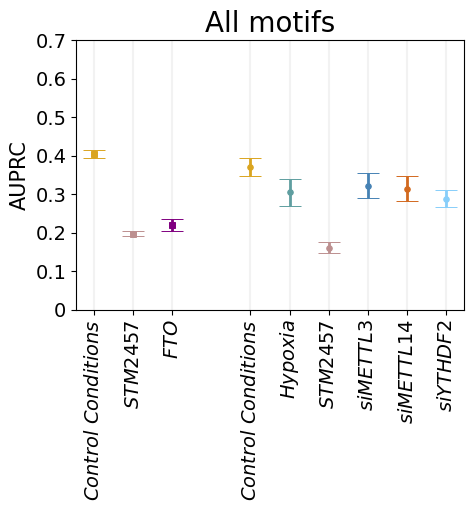

In [32]:
close("all")
ticks=[1,2,3,5,6,7,8,9,10]
figure(figsize=(5, 3.5))

errorbar(1,mean(A_HEK), yerr=std(A_HEK), marker="s", capsize=8,markersize=4,markeredgewidth=0.7, color="goldenrod", linewidth=2)
errorbar(2, mean(A_HEK_STM),yerr=std(A_HEK_STM),  markersize=4, capsize=8, marker="s", markeredgewidth=0.7, color="rosybrown", linewidth=2)
errorbar( 3,mean(A_FTO), yerr=std(A_FTO), markersize=4, marker="s",capsize=8, markeredgewidth=0.7, color="purple", linewidth=2)
errorbar(5,mean(A_HELA), yerr=std(A_HELA), markersize=4, marker="o",capsize=8, markeredgewidth=0.7, color="goldenrod", linewidth=2)
errorbar(6,mean(A_HPX),  yerr=std(A_HPX),markersize=4, marker="o", capsize=8,markeredgewidth=0.7, color="cadetblue", linewidth=2)
errorbar(7,mean(A_STM2457), yerr=std(A_STM2457), markersize=4, marker="o",capsize=8, markeredgewidth=0.7, color="rosybrown", linewidth=2)
errorbar(8,mean(A_siMETTL3), yerr=std(A_siMETTL3), markersize=4, marker="o", capsize=8, markeredgewidth=0.7,color="steelblue", linewidth=2)
errorbar(9,mean(A_siMETTL14), yerr=std(A_siMETTL14), markersize=4, marker="o", capsize=8, markeredgewidth=0.7,color="chocolate", linewidth=2)
errorbar(10, mean(A_siYTDH), yerr=std(A_siYTDH), markersize=4, marker="o", capsize=8,markeredgewidth=0.7, color="lightskyblue", linewidth=2)

yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7],["0", "0.1", "0.2", "0.3", "0.4", "0.5", "0.6" ,"0.7"])

ylabel("AUPRC", size=15)
[axvline(x=i, color="grey", zorder=0, alpha=0.1) for i in ticks]
xticks(ticks, [L"Control \ Conditions", L"STM2457", L"FTO", L"Control \ Conditions", L"Hypoxia", L"STM2457",L"siMETTL3", L"siMETTL14", L"siYTHDF2"], rotation=90)
title("All motifs", size=20)
ylim(0, 0.7)
xticks(fontsize=14)
yticks(fontsize=14)

gcf()

### Scaling DRACH motifs

In [33]:
tt=[mean(imb_HEK),mean(A_HEK),
mean(imb_HEK_STM), mean(A_HEK_STM),
 mean(imb_FTO),mean(A_FTO),
mean(imb_HELA),mean(A_HELA),
mean(imb_HPX),mean(A_HPX),
mean(imb_STM2457),mean(A_STM2457),
mean(imb_siMETTL3),mean(A_siMETTL3),
mean(imb_siMETTL14),mean(A_siMETTL14),
mean(imb_siYTDH), mean(A_siYTDH)];

In [34]:
corr=cor(convert(AbstractVector,transpose(reshape(tt, 2,9))[:,1]),convert(AbstractVector, transpose(reshape(tt, 2,9))[:,2]));

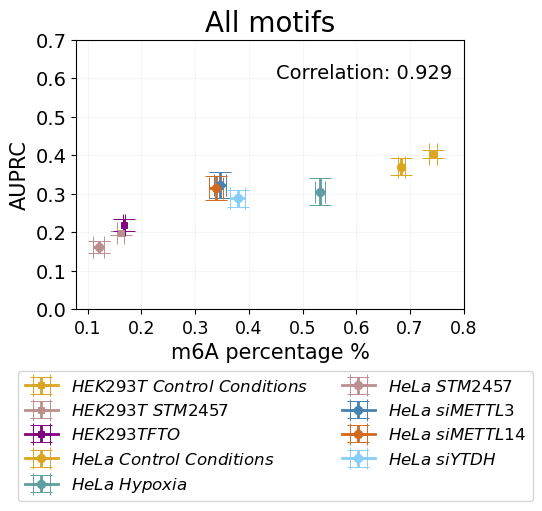

In [35]:
close("all")
figure(figsize=(5, 3.5))
errorbar(mean(imb_HEK)*100,mean(A_HEK), xerr=std(imb_HEK*100),yerr=std(A_HEK), marker="s", capsize=8,markersize=4,markeredgewidth=0.7, color="goldenrod", linewidth=2, label=L"HEK293T \ Control \ Conditions")
errorbar(mean(imb_HEK_STM)*100, mean(A_HEK_STM),xerr=std(imb_HEK_STM*100),yerr=std(A_HEK_STM),  markersize=4, capsize=8, marker="s", markeredgewidth=0.7, color="rosybrown", linewidth=2, label=L"HEK293T \ STM2457")
errorbar( mean(imb_FTO)*100,mean(A_FTO),xerr=std(imb_FTO*100), yerr=std(A_FTO), markersize=4, marker="s",capsize=8, markeredgewidth=0.7, color="purple", linewidth=2, label=L"HEK293T FTO")
errorbar(mean(imb_HELA)*100,mean(A_HELA),xerr=std(imb_HELA*100), yerr=std(A_HELA), markersize=6, marker="o",capsize=8, markeredgewidth=0.7, color="goldenrod", linewidth=2, label=L"HeLa \ Control \ Conditions")
errorbar(mean(imb_HPX)*100,mean(A_HPX), xerr=std(imb_HPX*100), yerr=std(A_HPX),markersize=6, marker="o", capsize=8,markeredgewidth=0.7, color="cadetblue", linewidth=2,label=L"HeLa \ Hypoxia")
errorbar(mean(imb_STM2457)*100,mean(A_STM2457), xerr=std(imb_STM2457*100),yerr=std(A_STM2457), markersize=6, marker="o",capsize=8, markeredgewidth=0.7, color="rosybrown", linewidth=2,label=L"HeLa \ STM2457")
errorbar(mean(imb_siMETTL3)*100,mean(A_siMETTL3),xerr=std(imb_siMETTL3*100), yerr=std(A_siMETTL3), markersize=6, marker="o", capsize=8, markeredgewidth=0.7,color="steelblue", linewidth=2,label=L"HeLa \ siMETTL3")
errorbar(mean(imb_siMETTL14)*100,mean(A_siMETTL14),xerr=std(imb_siMETTL14*100), yerr=std(A_siMETTL14), markersize=6, marker="o", capsize=8, markeredgewidth=0.7,color="chocolate", linewidth=2,label=L"HeLa \ siMETTL14")
errorbar(mean(imb_siYTDH)*100, mean(A_siYTDH), xerr=std(imb_siYTDH*100),yerr=std(A_siYTDH), markersize=6, marker="o", capsize=8,markeredgewidth=0.7, color="lightskyblue", linewidth=2,label=L"HeLa \ siYTDH")
legend(bbox_to_anchor=(1.2, -0.2),fontsize=12,ncol=2)
ylabel("AUPRC", size=15)
xlabel("m6A percentage %", size=15)
title("All motifs", size=20)
text(0.45, 0.6, "Correlation: $(round(corr, digits=3))", fontsize=14)
ylim(0, 0.7)
xticks([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8],[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
grid(alpha=0.1)
xticks(fontsize=12.5)
yticks(fontsize=14)
gcf()

# DRACH

In [36]:
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];

In [37]:
score_met_HEK_D,score_not_met_HEK_D=divide_score_DRACH(score_HEK, vcat(keys(MAP_mRNA_HEK)...), test_HEK)
score_met_FTO_D,score_not_met_FTO_D=divide_score_DRACH(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_FTO)
score_met_HEK_STM_D,score_not_met_HEK_STM_D=divide_score_DRACH(score_HEK, vcat(keys(MAP_mRNA_HEK)...), Test_HEK_STM2457);

In [38]:
score_met_HELA_D,score_not_met_HELA_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), test_HELA)
score_met_HPX_D,score_not_met_HPX_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_HPX)
score_met_STM2457_D,score_not_met_STM2457_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_STM2457)
score_met_siMETTL3_D,score_not_met_siMETTL3_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL3)
score_met_siMETTL14_D,score_not_met_siMETTL14_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siMETTL14)
score_met_siYTDH_D,score_not_met_siYTDH_D=divide_score_DRACH(score_HELA, vcat(keys(MAP_mRNA_HELA)...), Test_HELA_siYTDH);

In [39]:
#HEK293T
imb_HEK_D,tre_HEK_D,A_HEK_D, F_HEK_D=score_ava(score_met_HEK_D, score_not_met_HEK_D, sous_HEK ; pass=0.01, verb=true)
imb_FTO_D,tre_FTO_D,A_FTO_D, F_FTO_D=score_ava(score_met_FTO_D, score_not_met_FTO_D, sous_HEK ; pass=0.01, verb=true)
imb_HEK_STM_D,tre_HEK_STM_D,A_HEK_STM_D, F_HEK_STM_D=score_ava(score_met_HEK_STM_D, score_not_met_HEK_STM_D, sous_HEK ; pass=0.01, verb=true)
#HeLa
imb_HELA_D,tre_HELA_D, A_HELA_D, F_HELA_D=score_ava(score_met_HELA_D, score_not_met_HELA_D, sous_HELA ; pass=0.01, verb=true)
imb_STM2457_D,tre_STM2457_D,A_STM2457_D, F_STM2457_D=score_ava(score_met_STM2457_D, score_not_met_STM2457_D, sous_HELA ; pass=0.01, verb=true)
imb_HPX_D,tre_HPX_D,A_HPX_D, F_HPX_D=score_ava(score_met_HPX_D, score_not_met_HPX_D, sous_HELA ; pass=0.01, verb=true)
imb_siMETTL3_D,tre_siMETTL3_D, A_siMETTL3_D, F_siMETTL3_D=score_ava(score_met_siMETTL3_D, score_not_met_siMETTL3_D, sous_HELA ; pass=0.01, verb=true)
imb_siMETTL14_D,tre_siMETTL14_D, A_siMETTL14_D, F_siMETTL3_D=score_ava(score_met_siMETTL14_D, score_not_met_siMETTL14_D, sous_HELA ; pass=0.01, verb=true)
imb_siYTDH_D,tre_siYTDH_D, A_siYTDH_D, F_siYTDH_D=score_ava(score_met_siYTDH_D, score_not_met_siYTDH_D, sous_HELA ; pass=0.01, verb=true);

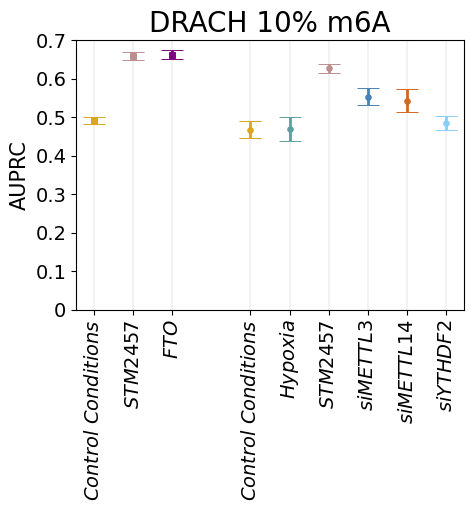

In [40]:
close("all")
ticks=[1,2,3,5,6,7,8,9,10]
figure(figsize=(5, 3.5))

errorbar(1,mean(A_HEK_D), yerr=std(A_HEK_D), marker="s", capsize=8,markersize=4,markeredgewidth=0.7, color="goldenrod", linewidth=2)
errorbar(2, mean(A_HEK_STM_D),yerr=std(A_HEK_STM_D),  markersize=4, capsize=8, marker="s", markeredgewidth=0.7, color="rosybrown", linewidth=2)
errorbar( 3,mean(A_FTO_D), yerr=std(A_FTO_D), markersize=4, marker="s",capsize=8, markeredgewidth=0.7, color="purple", linewidth=2)
errorbar(5,mean(A_HELA_D), yerr=std(A_HELA_D), markersize=4, marker="o",capsize=8, markeredgewidth=0.7, color="goldenrod", linewidth=2)
errorbar(6,mean(A_HPX_D),  yerr=std(A_HPX_D),markersize=4, marker="o", capsize=8,markeredgewidth=0.7, color="cadetblue", linewidth=2)
errorbar(7,mean(A_STM2457_D), yerr=std(A_STM2457_D), markersize=4, marker="o",capsize=8, markeredgewidth=0.7, color="rosybrown", linewidth=2)
errorbar(8,mean(A_siMETTL3_D), yerr=std(A_siMETTL3_D), markersize=4, marker="o", capsize=8, markeredgewidth=0.7,color="steelblue", linewidth=2)
errorbar(9,mean(A_siMETTL14_D), yerr=std(A_siMETTL14_D), markersize=4, marker="o", capsize=8, markeredgewidth=0.7,color="chocolate", linewidth=2)
errorbar(10, mean(A_siYTDH_D), yerr=std(A_siYTDH_D), markersize=4, marker="o", capsize=8,markeredgewidth=0.7, color="lightskyblue", linewidth=2)

yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7],["0", "0.1", "0.2", "0.3", "0.4", "0.5", "0.6" ,"0.7"])

ylabel("AUPRC", size=15)
[axvline(x=i, color="grey", zorder=0, alpha=0.1) for i in ticks]
xticks(ticks, [L"Control \ Conditions", L"STM2457", L"FTO", L"Control \ Conditions", L"Hypoxia", L"STM2457",L"siMETTL3", L"siMETTL14", L"siYTHDF2"], rotation=90)
title("DRACH 10% m6A", size=20)
xticks(fontsize=14)
yticks(fontsize=14)
ylim(0, 0.7)
gcf()

### Statistics DRACH motifs

> HEK293T

In [41]:
#HEK293T 
println("Number of m6A HEK293T Control Conditions: $(length(vcat(score_met_HEK_D...)))")
println("Number of A HEK293T Control Conditions: $(length(vcat(score_not_met_HEK_D...)))")
println("Number of m6A HEK293T FTO: $(length(vcat(score_met_FTO_D...)))")
println("Number of A HEK293T FTO: $(length(vcat(score_not_met_FTO_D...)))")
println("Number of m6A HEK293T STM2457: $(length(vcat(score_met_HEK_STM_D...)))")
println("Number of A HEK293T STM2457: $(length(vcat(score_not_met_HEK_STM_D...)))")

Number of m6A HEK293T Control Conditions: 28042
Number of A HEK293T Control Conditions: 302197
Number of m6A HEK293T FTO: 5597
Number of A HEK293T FTO: 324642
Number of m6A HEK293T STM2457: 5174
Number of A HEK293T STM2457: 325065


> HeLa

In [42]:
#HeLa
println("Number of m6A HeLa Control Conditions: $(length(vcat(score_met_HELA_D...)))")
println("Number of A HeLa Control Conditions: $(length(vcat(score_not_met_HELA_D...)))")
println("Number of m6A HeLa STM2457: $(length(vcat(score_met_STM2457_D...)))")
println("Number of A HeLa STM2457: $(length(vcat(score_not_met_STM2457_D...)))")
println("Number of m6A HeLa siMETTL3: $(length(vcat(score_met_siMETTL3_D...)))")
println("Number of A HeLa siMETTL3: $(length(vcat(score_not_met_siMETTL3_D...)))")
println("Number of m6A HeLa siMETTL14: $(length(vcat(score_met_siMETTL14_D...)))")
println("Number of A HeLa siMETTL14: $(length(vcat(score_not_met_siMETTL14_D...)))")
println("Number of m6A HeLa siYTHDF2: $(length(vcat(score_met_siYTDH_D...)))")
println("Number of A HeLa siYTHDF2: $(length(vcat(score_not_met_siYTDH_D...)))")
println("Number of m6A HeLa Hypoxia: $(length(vcat(score_met_HPX_D...)))")
println("Number of A HeLa Hypoxia: $(length(vcat(score_not_met_HPX_D...)))")

Number of m6A HeLa Control Conditions: 17711
Number of A HeLa Control Conditions: 203493
Number of m6A HeLa STM2457: 2791
Number of A HeLa STM2457: 218413
Number of m6A HeLa siMETTL3: 9335
Number of A HeLa siMETTL3: 211869
Number of m6A HeLa siMETTL14: 9140
Number of A HeLa siMETTL14: 212064
Number of m6A HeLa siYTHDF2: 10245
Number of A HeLa siYTHDF2: 210959
Number of m6A HeLa Hypoxia: 13395
Number of A HeLa Hypoxia: 207809


In [43]:
#Scoring all DRACH motifs with MEMAR-C
S_D=score_DRACH(M5, M6, Dict_DRACH, Ava/100);
N=18 #Number of DRACH motifs
ind=sortperm(vcat(values(S_D)...), rev=true) #indexes ordering of DRACH motifs based on the model score (decreasing order)
mot5A=vcat(keys(S_D)...)[ind] #ordered DRACH motifs by decreasing order
MOT5=[mot5A[i][1:2]*"A"*mot5A[i][3:4] for i in 1:length(mot5A)]; #adding central adenosine to consider 5-mers

In [44]:
mots_HEK=ava_dist_DRACH(test_HEK, MAP_mRNA_HEK, S_D, ind, sous_HEK)
mots_HEK_STM=ava_dist_DRACH(Test_HEK_STM2457, MAP_mRNA_HEK, S_D, ind, sous_HEK)
mots_FTO=ava_dist_DRACH(Test_HEK_FTO, MAP_mRNA_HEK, S_D, ind, sous_HEK)

mots_HELA=ava_dist_DRACH(test_HELA, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_YTH=ava_dist_DRACH(Test_HELA_siYTDH, MAP_mRNA_HELA, S_D, ind, sous_HELA)
mots_siMETTL3=ava_dist_DRACH(Test_HELA_siMETTL3, MAP_mRNA_HELA, S_D, ind, sous_HELA);

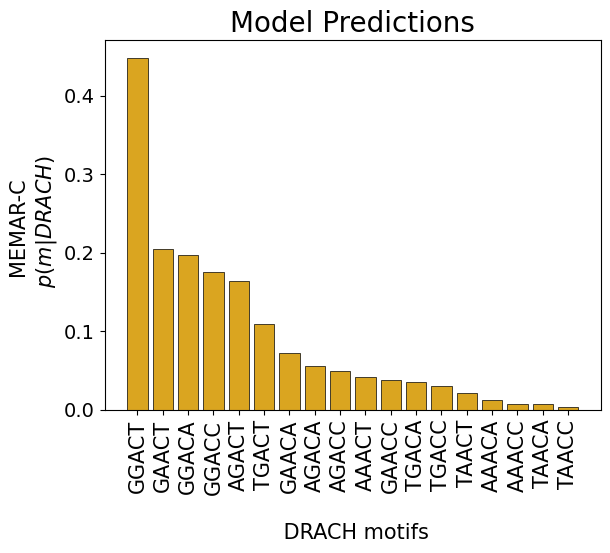

In [45]:
close("all")
bar(MOT5,[S_D[a[1:2]*a[4:5]] for a in MOT5], color="goldenrod", edgecolor="black", linewidth=0.5)
xticks(rotation=90, size=15)
xlabel("\n DRACH motifs", size=15)
yticks(size=14)
ylabel("MEMAR-C \n \$p(m|DRACH)\$", size=15)
title("Model Predictions", size=20)
gcf()

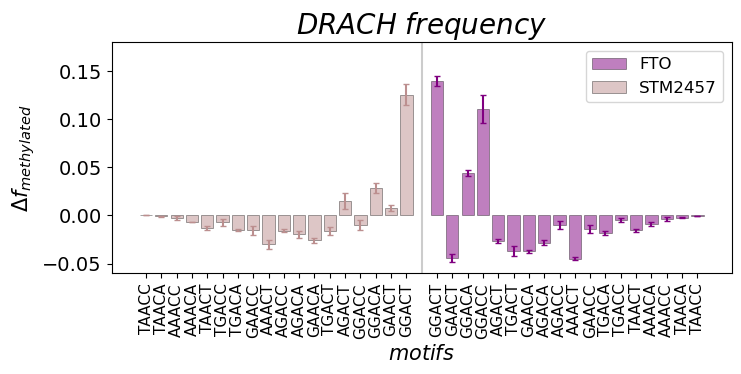

In [46]:
close("all")
figure(figsize=(8, 3))
bar(vcat(1:N...), mean.(eachrow(( hcat(mots_FTO...).-hcat(mots_HEK...)))),yerr=std.(eachrow(( hcat(mots_FTO...).-hcat(mots_HEK...)))), edgecolor="black", linewidth=0.5,capsize=2,color="purple", ecolor="purple",alpha=0.5, label="FTO")
bar(-vcat(1:N...), mean.(eachrow(( hcat(mots_HEK_STM...).-hcat(mots_HEK...)))),yerr=std.(eachrow(( hcat(mots_HEK_STM...).-hcat(mots_HEK...)))), edgecolor="black", linewidth=0.5,capsize=2,color="rosybrown", ecolor="rosybrown",alpha=0.5, label="STM2457")
ylim(-0.06, 0.18)
legend(fontsize=12)
title(L"DRACH \ frequency", size=20)
xticks(vcat(-vcat(1:N...),vcat(1:N...)), vcat(vcat(MOT5[1:N]),vcat(MOT5[1:N])), rotation=90)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
xticks(fontsize=11)
yticks(fontsize=14)
axvline(x=0, color="black", alpha=0.2)
gcf()

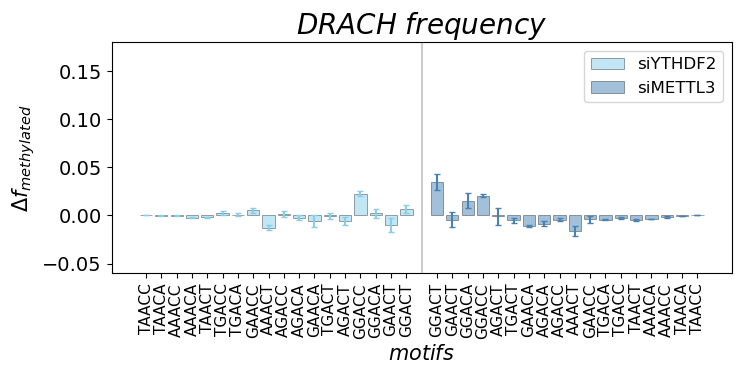

In [47]:
close("all")
figure(figsize=(8, 3))
bar(-vcat(1:N...), mean.(eachrow(( hcat(mots_YTH...).-hcat(mots_HELA...)))),yerr=std.(eachrow(( hcat(mots_YTH...).-hcat(mots_HELA...)))), edgecolor="black", linewidth=0.5,capsize=2,color="skyblue", ecolor="skyblue",alpha=0.5, label="siYTHDF2")
bar(vcat(1:N...), mean.(eachrow(( hcat(mots_siMETTL3...).-hcat(mots_HELA...)))),yerr=std.(eachrow(( hcat(mots_siMETTL3...).-hcat(mots_HELA...)))), edgecolor="black", linewidth=0.5,capsize=2,color="steelblue", ecolor="steelblue",alpha=0.5, label="siMETTL3")
legend(fontsize=12)
ylim(-0.06, 0.18)
xticks(vcat(-vcat(1:N...),vcat(1:N...)), vcat(vcat(MOT5[1:N]),vcat(MOT5[1:N])), rotation=90)
title(L"DRACH \ frequency", size=20)
axvline(x=0, color="black", alpha=0.2)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
xticks(fontsize=11)
yticks(fontsize=14)
gcf()

In [49]:
#Saving delta F profiles for section 6 analysis
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_STM2457.bin"), (mean.(eachrow(( hcat(mots_HEK_STM...).-hcat(mots_HEK...)))), std.(eachrow(( hcat(mots_HEK_STM...).-hcat(mots_HEK...))))) );
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_FTO.bin"),  (mean.(eachrow(( hcat(mots_FTO...).-hcat(mots_HEK...)))),std.(eachrow(( hcat(mots_FTO...).-hcat(mots_HEK...)))) ));
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_siEMTTL3.bin"), (mean.(eachrow(( hcat(mots_siMETTL3...).-hcat(mots_HELA...)))), std.(eachrow(( hcat(mots_siMETTL3...).-hcat(mots_HELA...))))));
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_siYTHDF2.bin"), (mean.(eachrow(( hcat(mots_YTH...).-hcat(mots_HELA...)))),std.(eachrow(( hcat(mots_YTH...).-hcat(mots_HELA...)))) ));